# Predicting Metacritic scores from game metadata

Can a game's **release year, genres, platforms and tags** tell us what Metacritic score it will get? This notebook explores the bundled RAWG snapshot (`data/raw/games.csv`) and evaluates the same model code that `python -m src.ml.train` runs and logs to MLflow.

Run it from the repository root:

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/metacritic-analysis.ipynb
```

Figures are written to `reports/figures/`.

In [1]:
import csv
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
os.environ.setdefault('DATABASE_URL', 'sqlite://')  # the app modules expect one; unused

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_val_score

from src.ml import features, train
from src.scripts.seed_from_csv import to_game_create

csv.field_size_limit(2**31 - 1)
FIGURES = Path('reports/figures')
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

2026/11/12 21:04:56 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\gkhne\Belgeler\GitHub\end-to-end-video-game-ml\.claude\worktrees\modernize-setup-df6520\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. Load the snapshot

Each CSV row goes through the seeder's own parser, so the notebook sees exactly what the database would.

In [2]:
rows = []
with open('data/raw/games.csv', newline='', encoding='utf-8') as f:
    for raw in csv.DictReader(f):
        game = to_game_create(raw)
        if game is None:
            continue
        rows.append({
            'game_id': game.id,
            'name': game.name,
            'release_year': float(game.released.year) if game.released else np.nan,
            'release_month': float(game.released.month) if game.released else np.nan,
            'esrb_rating': game.esrb_rating or '',
            'genres': features.join_names(g.name for g in game.genres),
            'platforms': features.join_names(p.name for p in game.platforms),
            'stores': features.join_names(s.name for s in game.stores),
            'tags': features.join_names(t.name for t in game.tags),
            'metacritic': game.metacritic,
            'rating': game.rating,
        })
games = pd.DataFrame(rows).drop_duplicates('game_id')
scored = games[games.metacritic.notna()].reset_index(drop=True)
print(f'{len(games):,} games, {len(scored):,} with a Metacritic score ({len(scored)/len(games):.0%})')

16,520 games, 5,116 with a Metacritic score (31%)


## 2. Who gets a Metacritic score?

Only a minority of games are reviewed by enough critics. Coverage depends strongly on the release year, which matters for how far the model's results generalize.

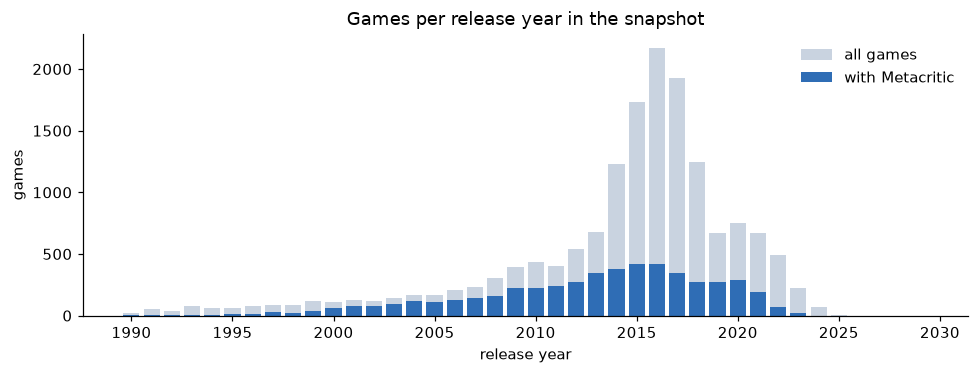

In [3]:
by_year = games.dropna(subset=['release_year']).groupby('release_year').agg(
    games=('game_id', 'size'), scored=('metacritic', 'count'))
by_year = by_year[by_year.index >= 1990]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_year.index, by_year.games, color='#c9d3e0', label='all games')
ax.bar(by_year.index, by_year.scored, color='#2f6db5', label='with Metacritic')
ax.set(title='Games per release year in the snapshot', xlabel='release year', ylabel='games')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURES / 'coverage_by_year.png')
plt.show()

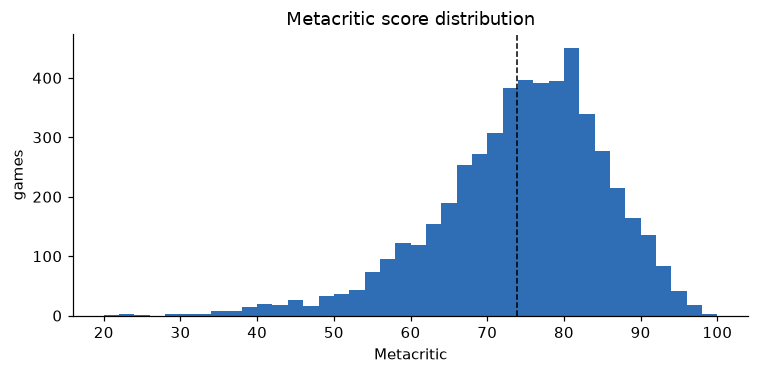

count    5116.0
mean       73.9
std        11.0
min        21.0
25%        68.0
50%        75.0
75%        81.0
max        99.0
Name: metacritic, dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(scored.metacritic, bins=range(20, 101, 2), color='#2f6db5')
ax.axvline(scored.metacritic.mean(), color='black', lw=1, ls='--')
ax.set(title='Metacritic score distribution', xlabel='Metacritic', ylabel='games')
fig.tight_layout(); fig.savefig(FIGURES / 'metacritic_distribution.png')
plt.show()
scored.metacritic.describe().round(1)

## 3. What moves the score?

Mean score per genre and the tags with the largest gap between games that have them and games that do not (tags on at least 2% of scored games). These are associations, not effects: a tag like Classic is partly a consequence of a game being well received.

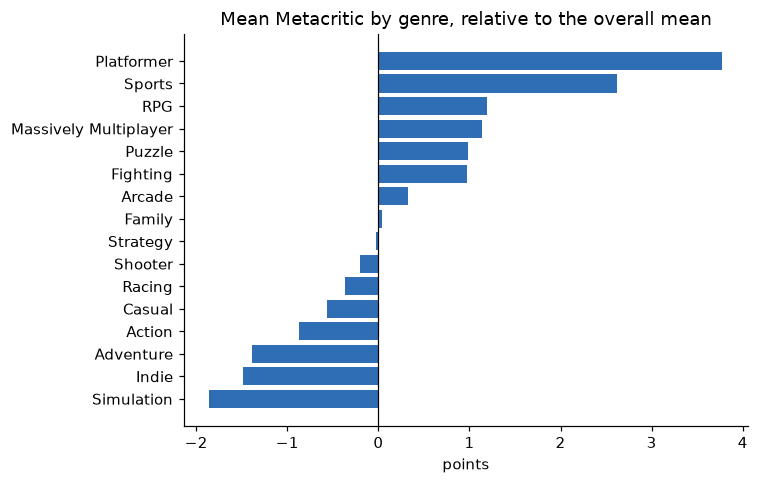

,mean,size
name,,
Simulation,72.1,605
Indie,72.4,1701
Adventure,72.5,1946
Action,73.0,2920
Casual,73.4,461
Racing,73.6,268
Shooter,73.7,676
Strategy,73.9,985
Family,74.0,90


In [5]:
def exploded(column):
    return scored.assign(name=scored[column].map(features.split_names)).explode('name').dropna(subset=['name'])

genre_stats = exploded('genres').groupby('name').metacritic.agg(['mean', 'size'])
genre_stats = genre_stats[genre_stats['size'] >= 50].sort_values('mean')
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(genre_stats.index, genre_stats['mean'] - scored.metacritic.mean(), color='#2f6db5')
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Mean Metacritic by genre, relative to the overall mean', xlabel='points')
fig.tight_layout(); fig.savefig(FIGURES / 'genre_effect.png')
plt.show()
genre_stats.round(1)

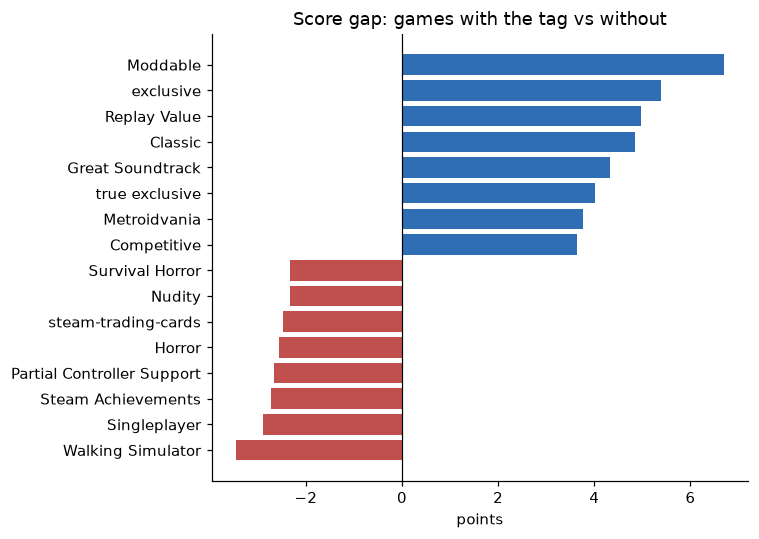

In [6]:
tag_rows = exploded('tags')
tag_counts = tag_rows.name.value_counts()
common_tags = tag_counts[tag_counts >= 0.02 * len(scored)].index
gaps = {}
for tag in common_tags:
    has = scored.tags.map(lambda t: tag in features.split_names(t))
    gaps[tag] = scored.metacritic[has].mean() - scored.metacritic[~has].mean()
gaps = pd.Series(gaps).sort_values()
top = pd.concat([gaps.head(8), gaps.tail(8)])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=np.where(top.values > 0, '#2f6db5', '#c0504d'))
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Score gap: games with the tag vs without', xlabel='points')
fig.tight_layout(); fig.savefig(FIGURES / 'tag_gaps.png')
plt.show()

## 4. Model evaluation

Same split, candidates and metrics as `src/ml/train.py`: about 20% of games are held out by a hash of their id, candidates are compared by 5-fold cross-validated MAE on the rest, and the baseline always predicts the training mean. RAWG's user `rating` is **not** a feature: it is only known after release and is missing for Steam and IGDB rows.

In [7]:
test_mask = train.is_test_game(scored.game_id)
X, y = scored[features.INPUT_COLUMNS], scored.metacritic.to_numpy(dtype=float)
X_train, X_test, y_train, y_test = X[~test_mask], X[test_mask], y[~test_mask], y[test_mask]
cv = KFold(n_splits=train.CV_FOLDS, shuffle=True, random_state=train.SEED)

results, fitted = [], {}
for name, (pipeline, _) in train.candidates().items():
    cv_mae = -cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error')
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
    results.append({'model': name, 'cv_mae': cv_mae.mean(), 'cv_mae_std': cv_mae.std(),
                    **train.regression_metrics(y_test, pipeline.predict(X_test), 'test')})
results = pd.DataFrame(results).set_index('model')
print(f'train: {len(X_train):,} games, test: {len(X_test):,} games')
results.round(3)

train: 4,099 games, test: 1,017 games


,cv_mae,cv_mae_std,test_mae,test_rmse,test_r2,test_band_accuracy_balanced,test_mae_unfavourable,test_mae_mixed,test_mae_favourable,test_mae_acclaim
model,,,,,,,,,,
baseline_mean,8.619,0.174,8.275,10.872,-0.000,0.250,32.479,6.855,6.777,18.424
ridge,7.723,0.204,7.619,10.028,0.149,0.320,27.197,6.418,6.743,13.314
hist_gradient_boosting,7.061,0.194,6.811,9.197,0.284,0.357,26.235,6.528,5.300,10.635


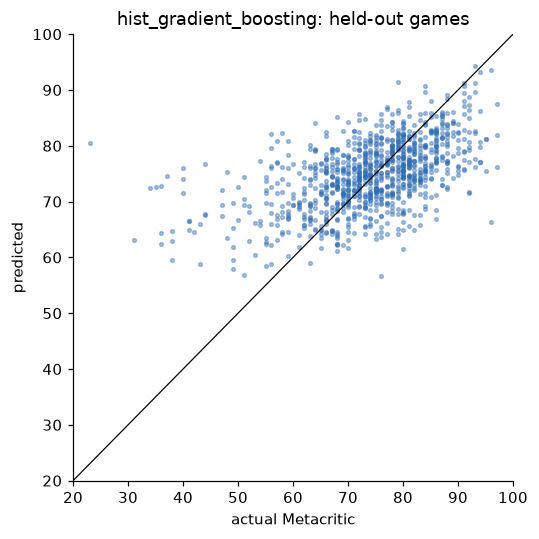

In [8]:
best_name = results.drop('baseline_mean').cv_mae.idxmin()
best = fitted[best_name]
pred = np.clip(best.predict(X_test), 0, 100)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, pred, s=6, alpha=0.4, color='#2f6db5')
ax.plot([20, 100], [20, 100], color='black', lw=0.8)
ax.set(xlim=(20, 100), ylim=(20, 100), xlabel='actual Metacritic', ylabel='predicted',
       title=f'{best_name}: held-out games')
fig.tight_layout(); fig.savefig(FIGURES / 'predicted_vs_actual.png')
plt.show()

Permutation importance per input: how much the test MAE rises when that input is shuffled across games.

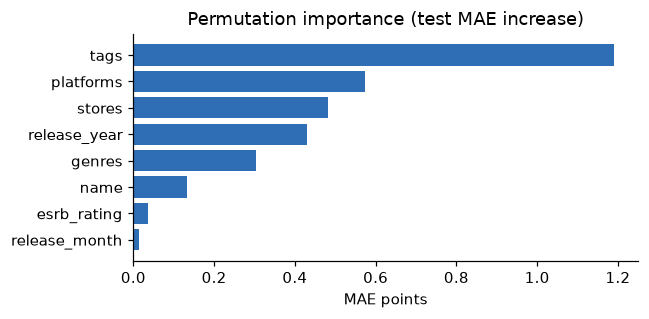

release_month    0.015
esrb_rating      0.037
name             0.133
genres           0.303
release_year     0.430
stores           0.482
platforms        0.575
tags             1.190
dtype: float64

In [9]:
importance = pd.Series(train.group_importance(best, X_test, y_test)).sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(importance.index, importance.values, color='#2f6db5')
ax.set(title='Permutation importance (test MAE increase)', xlabel='MAE points')
fig.tight_layout(); fig.savefig(FIGURES / 'permutation_importance.png')
plt.show()
importance.round(3)

In [10]:
errors = scored[test_mask].assign(predicted=pred.round(1))
errors['error'] = errors.predicted - errors.metacritic
print('Mean error by actual-score band (positive = model too optimistic):')
print(errors.groupby(pd.cut(errors.metacritic, [0, 60, 70, 80, 90, 100])).error.agg(['mean', 'size']).round(1))

Mean error by actual-score band (positive = model too optimistic):
            mean  size
metacritic            
(0, 60]     17.7   101
(60, 70]     5.2   230
(70, 80]    -0.5   406
(80, 90]    -6.1   235
(90, 100]  -10.5    45


## 5. Findings

The numbers below are printed from this run, so they stay true when the data changes.

In [11]:
b = results.loc['baseline_mean']; m = results.loc[best_name]
print(f'Best model: {best_name}')
print(f'Test MAE {m.test_mae:.2f} vs baseline {b.test_mae:.2f} '
      f'({1 - m.test_mae / b.test_mae:.0%} lower), R² {m.test_r2:.2f}')
print(f'Most informative input: {importance.idxmax()}')

Best model: hist_gradient_boosting
Test MAE 6.81 vs baseline 8.28 (18% lower), R² 0.28
Most informative input: tags


- Metadata alone explains only part of the variance: the model beats the mean baseline clearly but still misses by several points on average.
- It regresses toward the mean: very low and very high scores are pulled to the middle (see the error table), which is expected when quality itself is not observed.
- Coverage is uneven across years, so the model is best supported for the years with many reviewed games.
- Natural next steps: text features from descriptions, developer/publisher history, and pre-release signals such as wishlists or follower counts.